In [2]:
import numpy as np 
import pandas as pd 
from pathlib import Path
import matplotlib.pyplot as plt


#loading datatset
PROJECT_ROOT = Path("..")
DATA_PATH = PROJECT_ROOT/"data"/"Round10_traces.csv"
df = pd.read_csv(DATA_PATH,header=None)

print("Dataset shape :",df.shape)
print(df.head())

Dataset shape : (100000, 201)
                                0         1         2         3         4    \
0  e6567b07c14ffa75e98d96699ee5e5be -0.001953 -0.006836 -0.004883 -0.011719   
1  e5fccffc3f8ceee27c84c9ef33bfe92c -0.000977 -0.008789 -0.001953 -0.014648   
2  3151d58d01c7b2ea520e8487055c337e -0.001953 -0.010742 -0.004883 -0.010742   
3  8ace0b388dd39df4c8c0150c4211d9fa -0.004883 -0.009766 -0.006836 -0.014648   
4  c1a77e77566932cbcd6cdc3f8af58313  0.000000 -0.004883 -0.000977 -0.008789   

        5         6         7         8         9    ...       191       192  \
0 -0.001953 -0.179688 -0.149414 -0.095703 -0.018555  ...  0.004883 -0.003906   
1 -0.001953 -0.184570 -0.153320 -0.094727 -0.020508  ...  0.007812 -0.003906   
2 -0.003906 -0.184570 -0.148438 -0.093750 -0.017578  ...  0.006836 -0.004883   
3 -0.006836 -0.178711 -0.147461 -0.095703 -0.021484  ...  0.003906 -0.007812   
4 -0.000977 -0.165039 -0.136719 -0.087891 -0.014648  ...  0.008789  0.000000   

        193   

In [3]:
#seperating ciphertext and traces
#column 0     : ciphertext
#column 1-200 : traces

ciphertext_hex = df.iloc[:,0].astype(str)
traces = df.iloc[:,1:].to_numpy(dtype =np.float32)
print("Ciphertexts:", ciphertext_hex.shape)
print("Traces:", traces.shape)

Ciphertexts: (100000,)
Traces: (100000, 200)


In [9]:
#validating ciphertext and checking trace datatype

lengthCount = ciphertext_hex.str.len().value_counts()
print(lengthCount)
invalid_hex = ~ciphertext_hex.str.fullmatch(r"[0-9a-fA-F]{32}")
print("Invalid ciphertexts:", invalid_hex.sum())

print("Trace dtype:", traces.dtype)
print("Trace shape:", traces.shape)

0
32    100000
Name: count, dtype: int64
Invalid ciphertexts: 0
Trace dtype: float32
Trace shape: (100000, 200)


In [8]:
#converting ciphertexts to 16 bytes
ciphertexts = np.array(
    [[int(x, 16) for x in row]
     for row in ciphertext_hex.str.findall(r"..")],
    dtype=np.uint8
)

print("Ciphertext byte array shape:", ciphertexts.shape)
print(ciphertexts[:3])


Ciphertext byte array shape: (100000, 16)
[[230  86 123   7 193  79 250 117 233 141 150 105 158 229 229 190]
 [229 252 207 252  63 140 238 226 124 132 201 239  51 191 233  44]
 [ 49  81 213 141   1 199 178 234  82  14 132 135   5  92  51 126]]


In [10]:
#checking NaNs and infinities

print("NaN values:", np.isnan(traces).sum())
print("Infinite values:", np.isinf(traces).sum())

NaN values: 0
Infinite values: 0


In [12]:
#statistics
print("Minimum:", traces.min())
print("Maximum:", traces.max())
print("Mean:", traces.mean())
print("Standard deviation:", traces.std())

sample_mean = traces.mean(axis=0)
sample_std = traces.std(axis=0)

print("Mean shape:", sample_mean.shape)
print("Std shape:", sample_std.shape)

Minimum: -0.20214844
Maximum: 0.07324219
Mean: -0.011052687
Standard deviation: 0.040505
Mean shape: (200,)
Std shape: (200,)


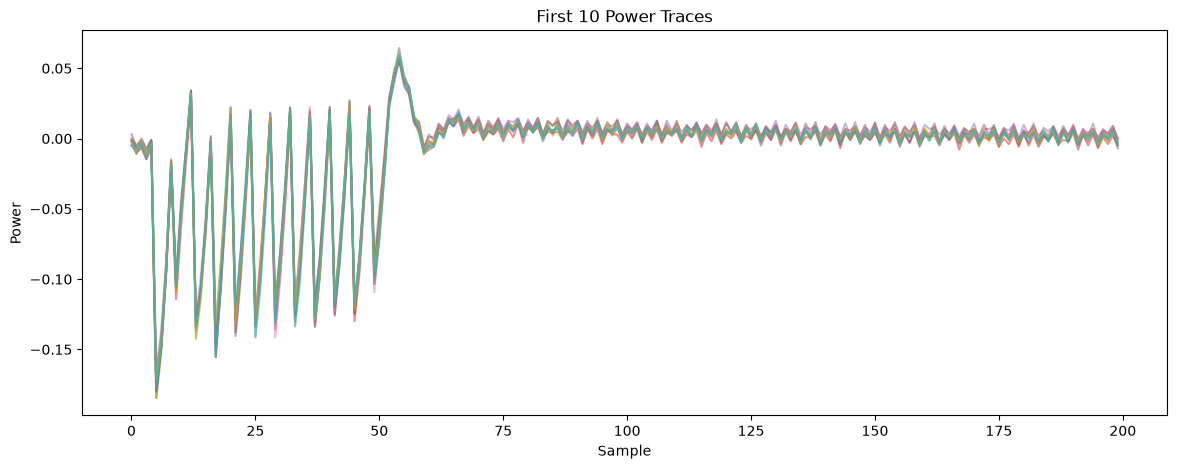

In [13]:
#plotting first 10 traces

plt.figure(figsize=(14, 5))

for i in range(10):
    plt.plot(traces[i], alpha=0.5)

plt.xlabel("Sample")
plt.ylabel("Power")
plt.title("First 10 Power Traces")
plt.show()

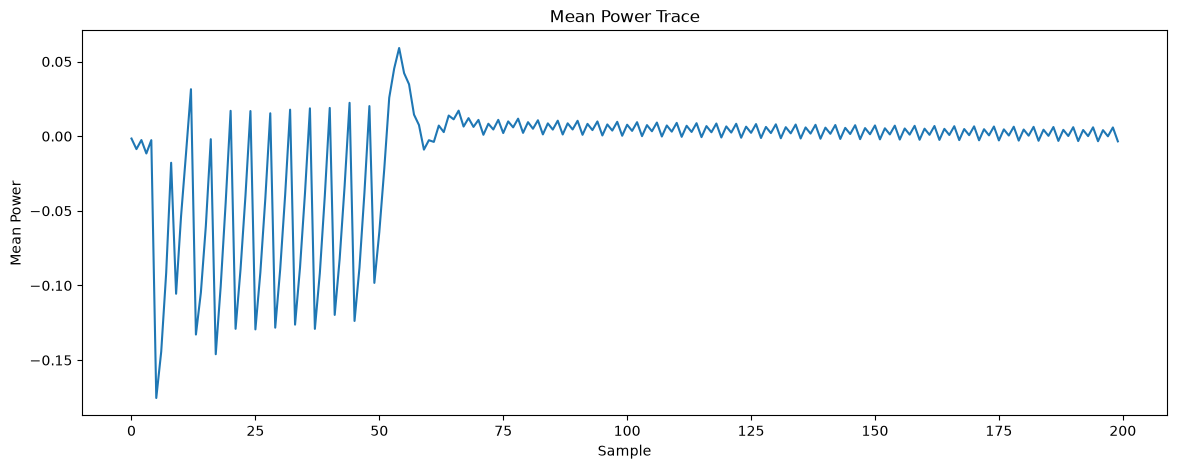

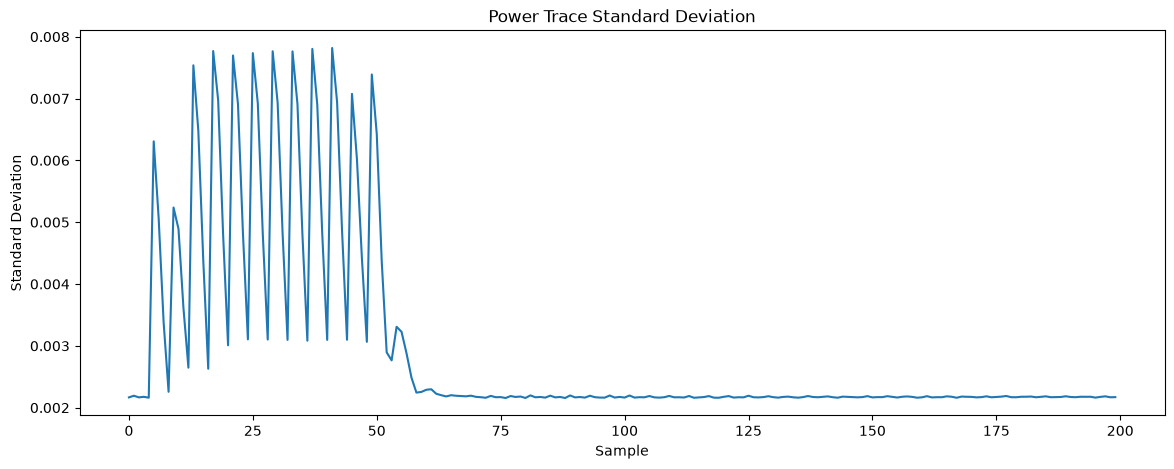

In [14]:
#plotting mean and std
plt.figure(figsize=(14, 5))

plt.plot(sample_mean)

plt.xlabel("Sample")
plt.ylabel("Mean Power")
plt.title("Mean Power Trace")
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(sample_std)

plt.xlabel("Sample")
plt.ylabel("Standard Deviation")
plt.title("Power Trace Standard Deviation")
plt.show()

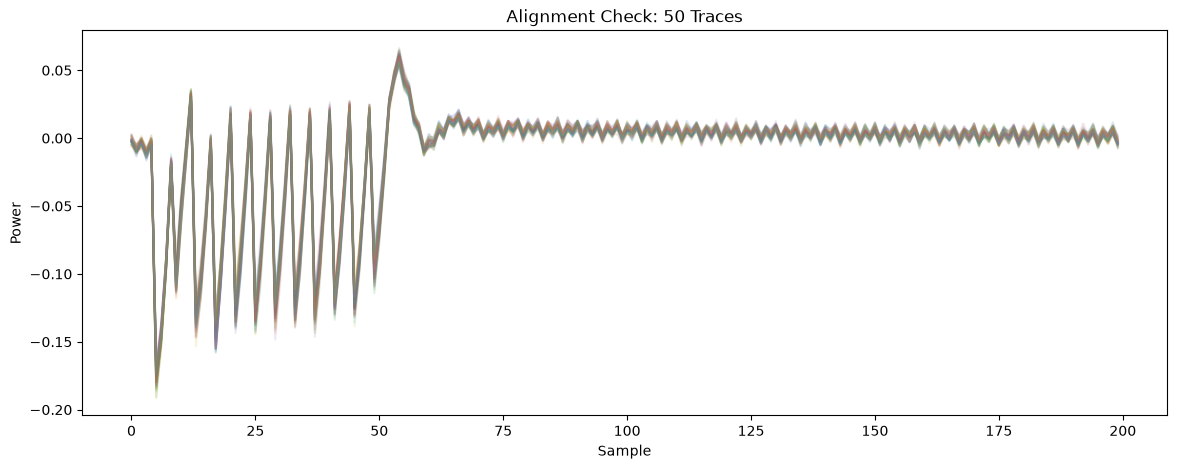

In [15]:
#checking trace alignment
plt.figure(figsize=(14, 5))

for i in range(50):
    plt.plot(traces[i], alpha=0.15)

plt.xlabel("Sample")
plt.ylabel("Power")
plt.title("Alignment Check: 50 Traces")
plt.show()

In [17]:
#checking flat samples
lowest_variance_indices = np.argsort(sample_std)[:20]

print("Lowest variance samples:")
print(lowest_variance_indices)

print("Their standard deviations:")
print(sample_std[lowest_variance_indices])

highest_variance_indices = np.argsort(sample_std)[-20:][::-1]

print("Highest variance samples:")
print(highest_variance_indices)

print("Their standard deviations:")
print(sample_std[highest_variance_indices])

Lowest variance samples:
[ 88  76  80 114  72 167 119 159 143   4 135 118 131 107  96  84 195  92
 102 122]
Their standard deviations:
[0.00215649 0.00215655 0.00215715 0.0021604  0.00216044 0.00216049
 0.00216057 0.00216126 0.00216132 0.00216144 0.0021618  0.00216214
 0.00216235 0.00216251 0.00216258 0.00216262 0.00216267 0.00216285
 0.0021631  0.00216326]
Highest variance samples:
[41 37 17 29 33 25 21 13 49 45 18 42 30 26 34 22 38 14 50  5]
Their standard deviations:
[0.00781772 0.00780334 0.00776856 0.00776482 0.00776287 0.00773444
 0.00769661 0.00753771 0.00738979 0.00707555 0.00697418 0.00693889
 0.00693386 0.0069225  0.00691262 0.00690968 0.00689837 0.00647992
 0.00642717 0.00630794]


In [18]:
#checking duplicate ciphertexts 
unique_ciphertexts = np.unique(ciphertexts, axis=0)

print("Unique ciphertexts:", len(unique_ciphertexts))
print("Total traces:", len(ciphertexts))

Unique ciphertexts: 100000
Total traces: 100000


In [20]:
Path("results/preprocessing").mkdir(
    parents=True,
    exist_ok=True
)

np.savez_compressed(
    "results/preprocessing/preprocessed_data.npz",
    ciphertexts=ciphertexts,
    traces=traces
)